# River-1 quickstart

Simulate the weekly MMM dataset of PyMC-Marketing's
[MMM example](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_example.html) with its
adstock and saturation transformers, load River-1 from the Hub and decompose the sales: the model
sees the outcome of the first 80% of the weeks (context) and decomposes both the context and the
remaining 20% (query), with no model fit. Every chart comes from `model.plot`.

Requires `pip install 'pymc-mfm[hub,diagnostics,examples]'` and access to the private
`pymc-labs/mfm` repository (`hf auth login`). Add the `interactive` extra for plotly charts.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib
import numpy as np
import pandas as pd
import torch
import xarray as xr
from pymc_marketing.mmm.transformers import geometric_adstock, logistic_saturation

from pymc_mfm import from_pretrained

# 200 dpi, the resolution of PyMC-Marketing's notebooks (100 dpi, retina): sharper, larger figures.
matplotlib.rcParams["figure.dpi"] = 200

## 1. Load River-1

The bundle (about 10 MB) is downloaded into a temporary folder at a pinned repository commit.

In [2]:
workspace = TemporaryDirectory(prefix="river-1-")
model = from_pretrained(
    "pymc-labs/mfm",
    profile="river-1",
    revision="970e6095f14824d7e25ecace7e20a47bebde35b8",
    cache_dir=Path(workspace.name) / "hub",
)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
model.config

2,443,583 parameters


ModelConfig(d_model=128, n_layers=4, n_heads=8, d_ff=512, flow_hidden=256, n_controls=10, n_demand=1)

## 2. Generate the data

The PyMC-Marketing data-generating process: two channels with geometric adstock (an eight-week
window, lags 0–7) and logistic saturation, both from `pymc_marketing.mmm.transformers`, a trend, yearly
seasonality, two one-week events, an intercept and Gaussian noise, in sales units (thousands). The
series has 208 weeks, the history length River-1 was trained on.

In [3]:
seed = sum(map(ord, "mmm"))
rng = np.random.default_rng(seed=seed)
N_WEEKS = 208
dates = np.datetime64("2018-04-02") + 7 * np.arange(N_WEEKS)
dayofyear = (dates - dates.astype("datetime64[Y]")).astype(int) + 1

x1 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x1 = np.where(x1 > 0.9, x1, x1 / 2)
x2 = rng.uniform(low=0.0, high=1.0, size=N_WEEKS)
x2 = np.where(x2 > 0.8, x2, 0.0)

In [4]:
SCALE = 1_000
ADSTOCK_L_MAX = 8
media_parameters = {
    "x1": {"alpha": 0.4, "lam": 4.0, "beta": 3.0},
    "x2": {"alpha": 0.2, "lam": 3.0, "beta": 2.0},
}
x1_adstock = geometric_adstock(
    xr.DataArray(x1, dims="week"),
    alpha=media_parameters["x1"]["alpha"],
    l_max=ADSTOCK_L_MAX,
    normalize=True,
    dim="week",
)
x2_adstock = geometric_adstock(
    xr.DataArray(x2, dims="week"),
    alpha=media_parameters["x2"]["alpha"],
    l_max=ADSTOCK_L_MAX,
    normalize=True,
    dim="week",
)
media = np.column_stack(
    [
        media_parameters["x1"]["beta"]
        * logistic_saturation(x1_adstock, lam=media_parameters["x1"]["lam"]).eval(),
        media_parameters["x2"]["beta"]
        * logistic_saturation(x2_adstock, lam=media_parameters["x2"]["lam"]).eval(),
    ]
)
trend = (np.linspace(start=0.0, stop=50, num=N_WEEKS) + 10) ** (1 / 4) - 1
seasonality = 0.5 * (
    -np.sin(2 * 2 * np.pi * dayofyear / 365.5) + np.cos(1 * 2 * np.pi * dayofyear / 365.5)
)
events = np.column_stack(
    [dates == np.datetime64("2019-05-13"), dates == np.datetime64("2020-09-14")]
).astype(float)
epsilon = rng.normal(loc=0.0, scale=0.25, size=N_WEEKS)

# True contributions in sales units.
baseline = SCALE * (2.0 + trend + seasonality)
channel_truth = SCALE * media
event_truth = SCALE * events * [1.5, 2.5]
y = baseline + channel_truth.sum(axis=1) + event_truth.sum(axis=1) + SCALE * epsilon

data = pd.DataFrame(
    {
        "date": dates,
        "sales": y,
        "x1": x1,
        "x2": x2,
        "event_1": events[:, 0],
        "event_2": events[:, 1],
    }
)
# The true contributions by date; the recovery charts draw them as dashed lines.
truth = pd.DataFrame(
    {
        "baseline": baseline,
        "x1": channel_truth[:, 0],
        "x2": channel_truth[:, 1],
        "event_1": event_truth[:, 0],
        "event_2": event_truth[:, 1],
    },
    index=pd.DatetimeIndex(dates),
)

## 3. Give the model its context

`add_context` stores the history and the column roles: the date, the outcome, the spend
channels and the controls. River-1 has 10 control slots: the two events fill the first two and
the rest are masked. Intercept, trend and seasonality belong to the model's baseline. The model
reads spend and controls for every week, but sales only for the context weeks.

In [5]:
CONTEXT = int(0.8 * N_WEEKS)
history, future = data.iloc[:CONTEXT], data.iloc[CONTEXT:]
model.add_context(
    history,
    date_column="date",
    target_column="sales",
    channel_columns=["x1", "x2"],
    control_columns=["event_1", "event_2"],
)
print(f"{CONTEXT} context weeks, {N_WEEKS - CONTEXT} query weeks")

166 context weeks, 42 query weeks


## 4. Decompose

`inference` decomposes the query weeks with 1,000 posterior draws instead of the default 2,000.
The query frame keeps its sales column: the model never reads it, and the charts draw it as the
held-out outcome. The first chart that shows context weeks samples the context window once, with
the same settings, and every later chart reuses those draws.

In [6]:
torch.manual_seed(0)
query = model.inference(future, n_samples=1_000)
query.components.shape  # [draw, week, component]

(1000, 42, 17)

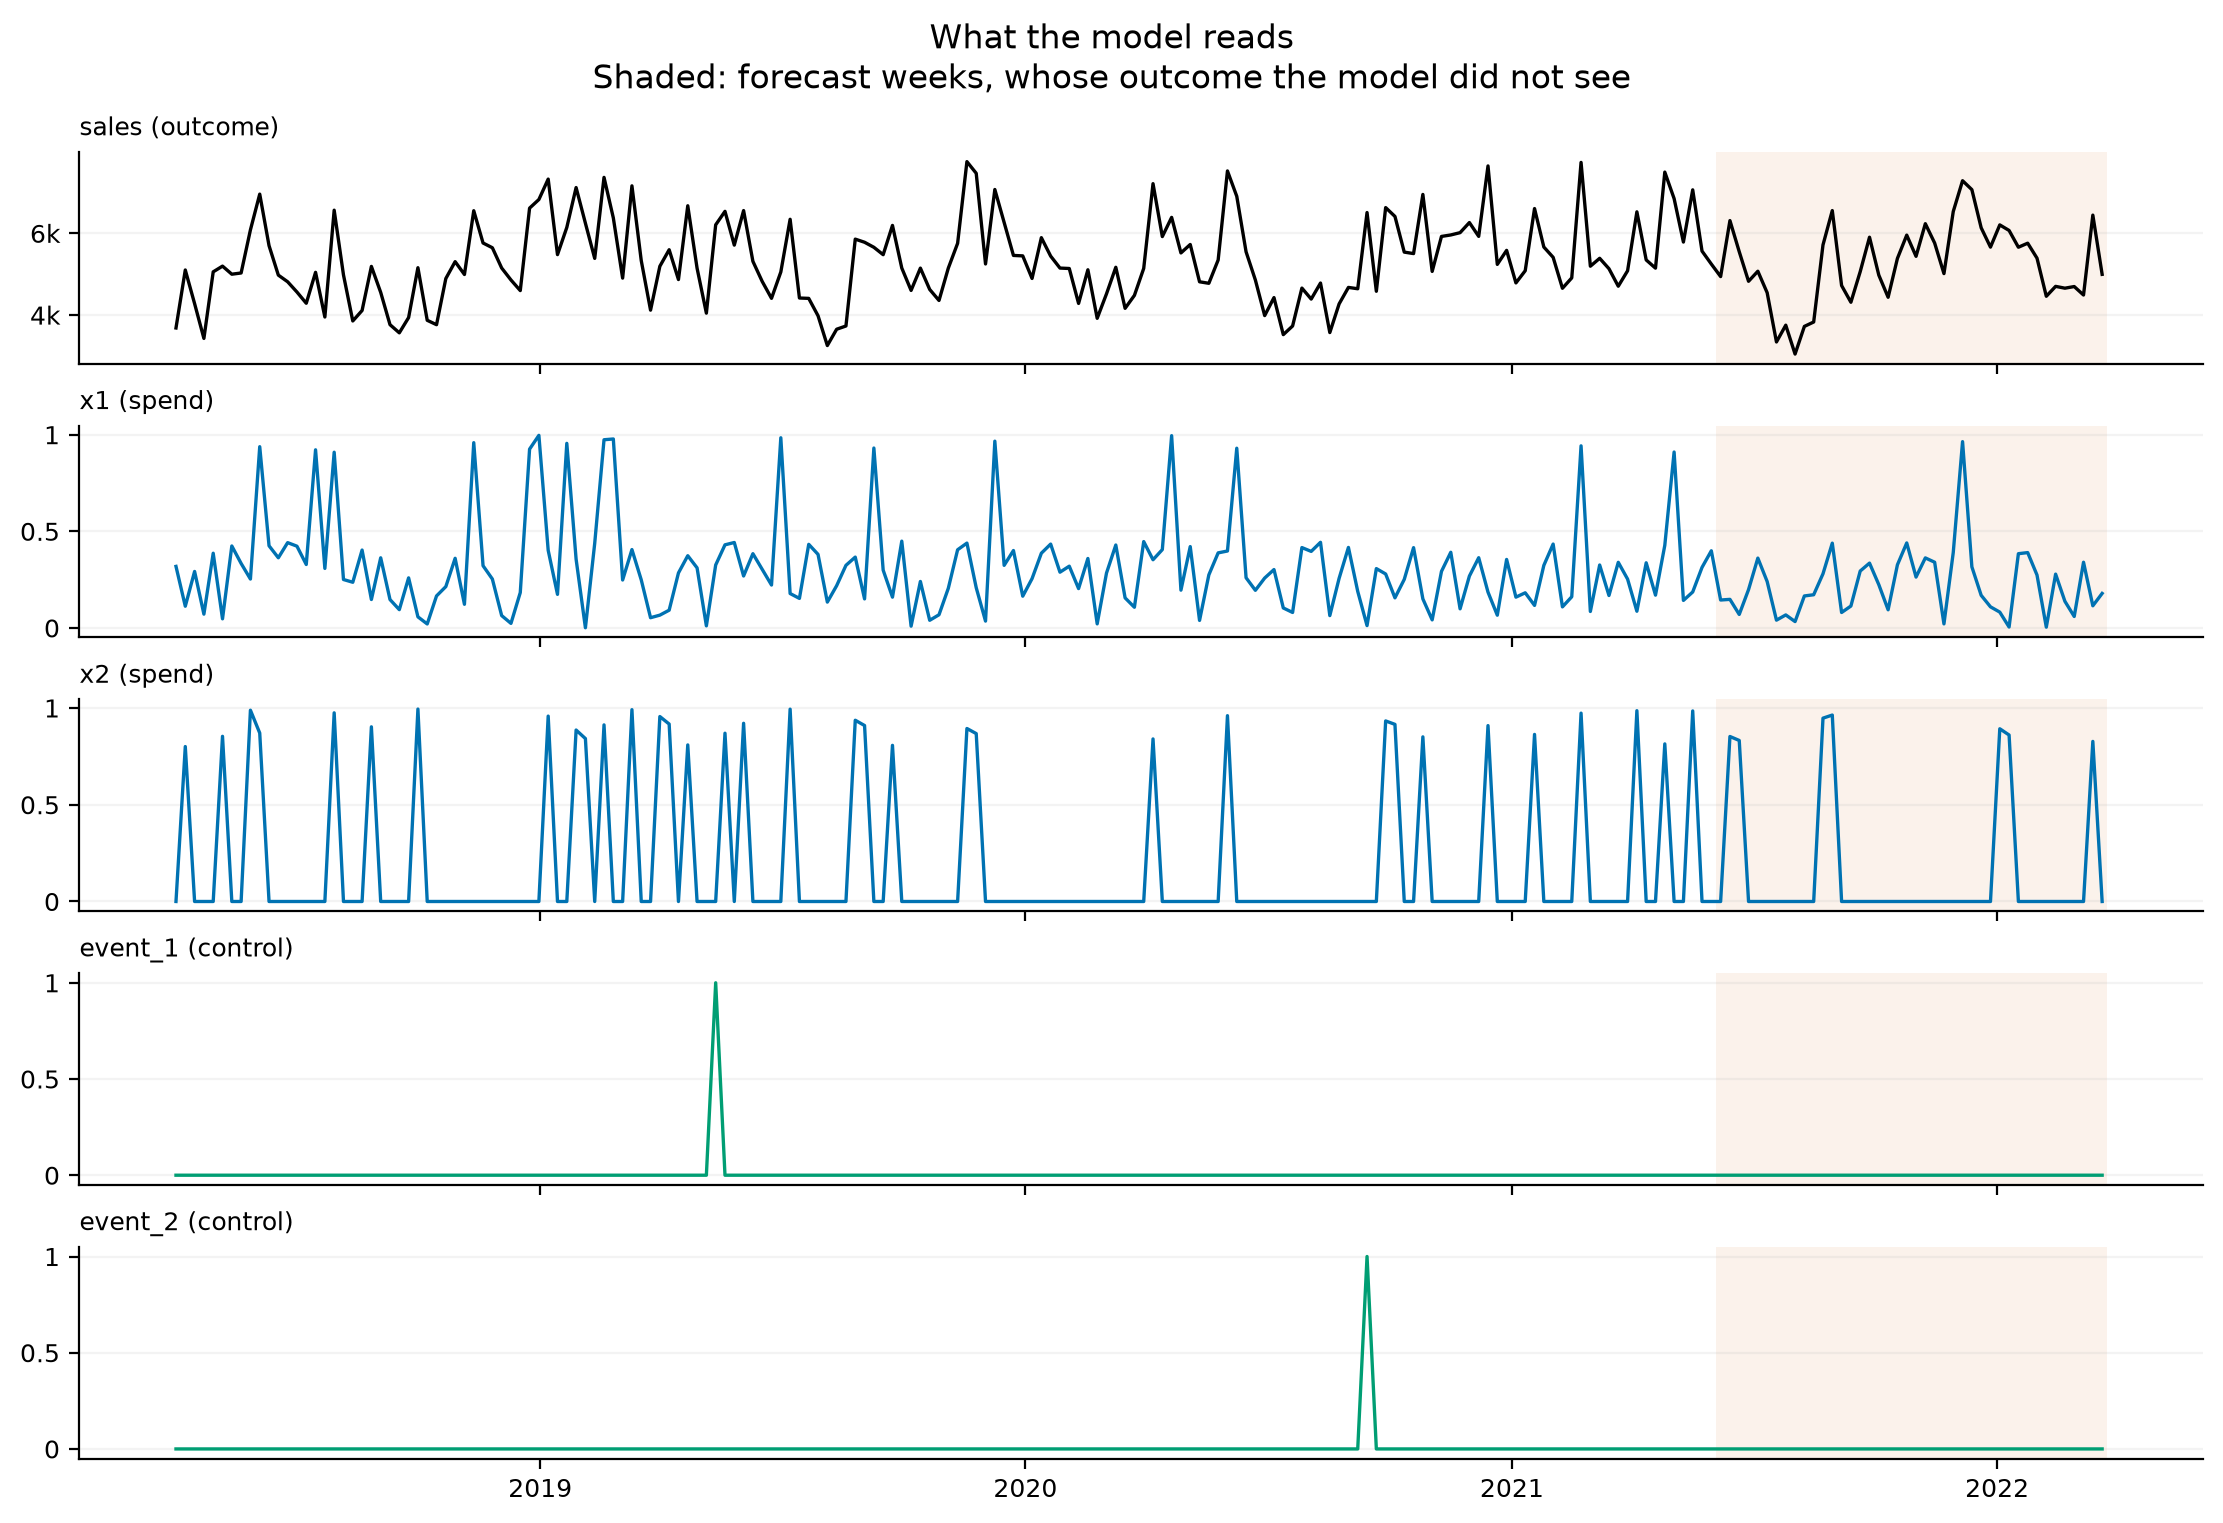

In [7]:
model.plot.inputs()

### Input-token usage

`input_usage` counts input tokens without running the model. Counts are per request, not
cumulative: a one-week plan changes the query and total counts while the context stays fixed.
Each inference result records the counts of its own request.

In [8]:
print("Context only:", model.input_usage())
print("One-week plan:", model.input_usage(future.iloc[:1]))
print("This query:", query.provenance["input_usage"])

Context only: {'context': {'steps': 166, 'allocated_tokens': 2158, 'represented_tokens': 830}}
One-week plan: {'context': {'steps': 166, 'allocated_tokens': 2158, 'represented_tokens': 830}, 'query': {'steps': 1, 'allocated_tokens': 13, 'represented_tokens': 5}, 'total': {'allocated_tokens': 2171, 'represented_tokens': 835}}
This query: {'context': {'steps': 166, 'allocated_tokens': 2158, 'represented_tokens': 830}, 'query': {'steps': 42, 'allocated_tokens': 546, 'represented_tokens': 210}, 'total': {'allocated_tokens': 2704, 'represented_tokens': 1040}}


## 5. Sales

The expected sales are the sum of the components; they exclude observation noise. The model
never saw the sales of the shaded weeks. The cards score the mean line against the observed
sales, with the spread of each score over the draws.

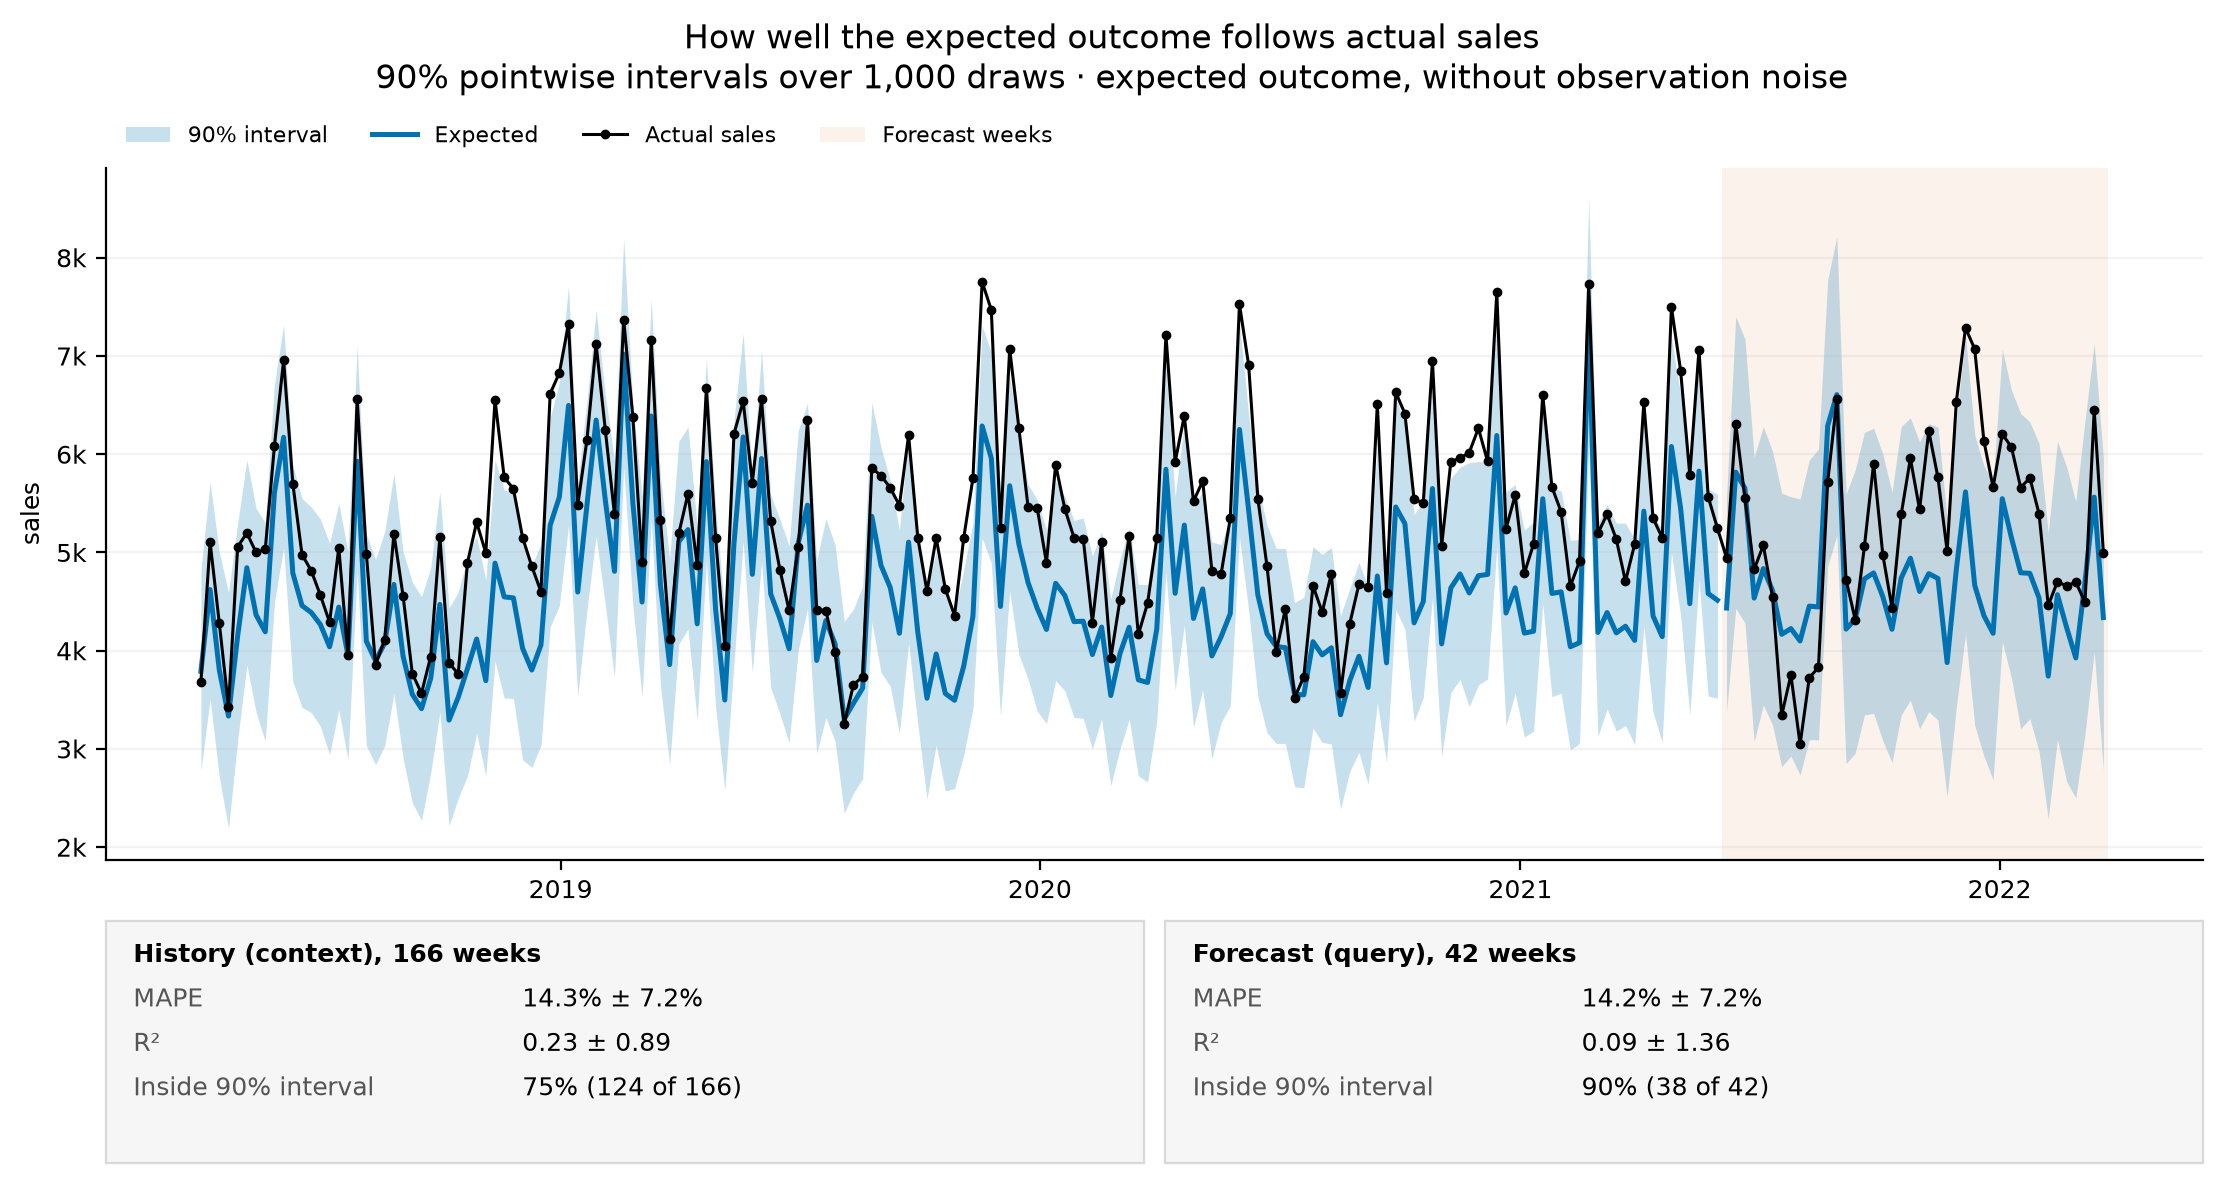

In [9]:
model.plot.fit()

## 6. Contributions

Weekly posterior means of every component, stacked: positive contributions above zero,
negative ones below. The black line is the observed sales.

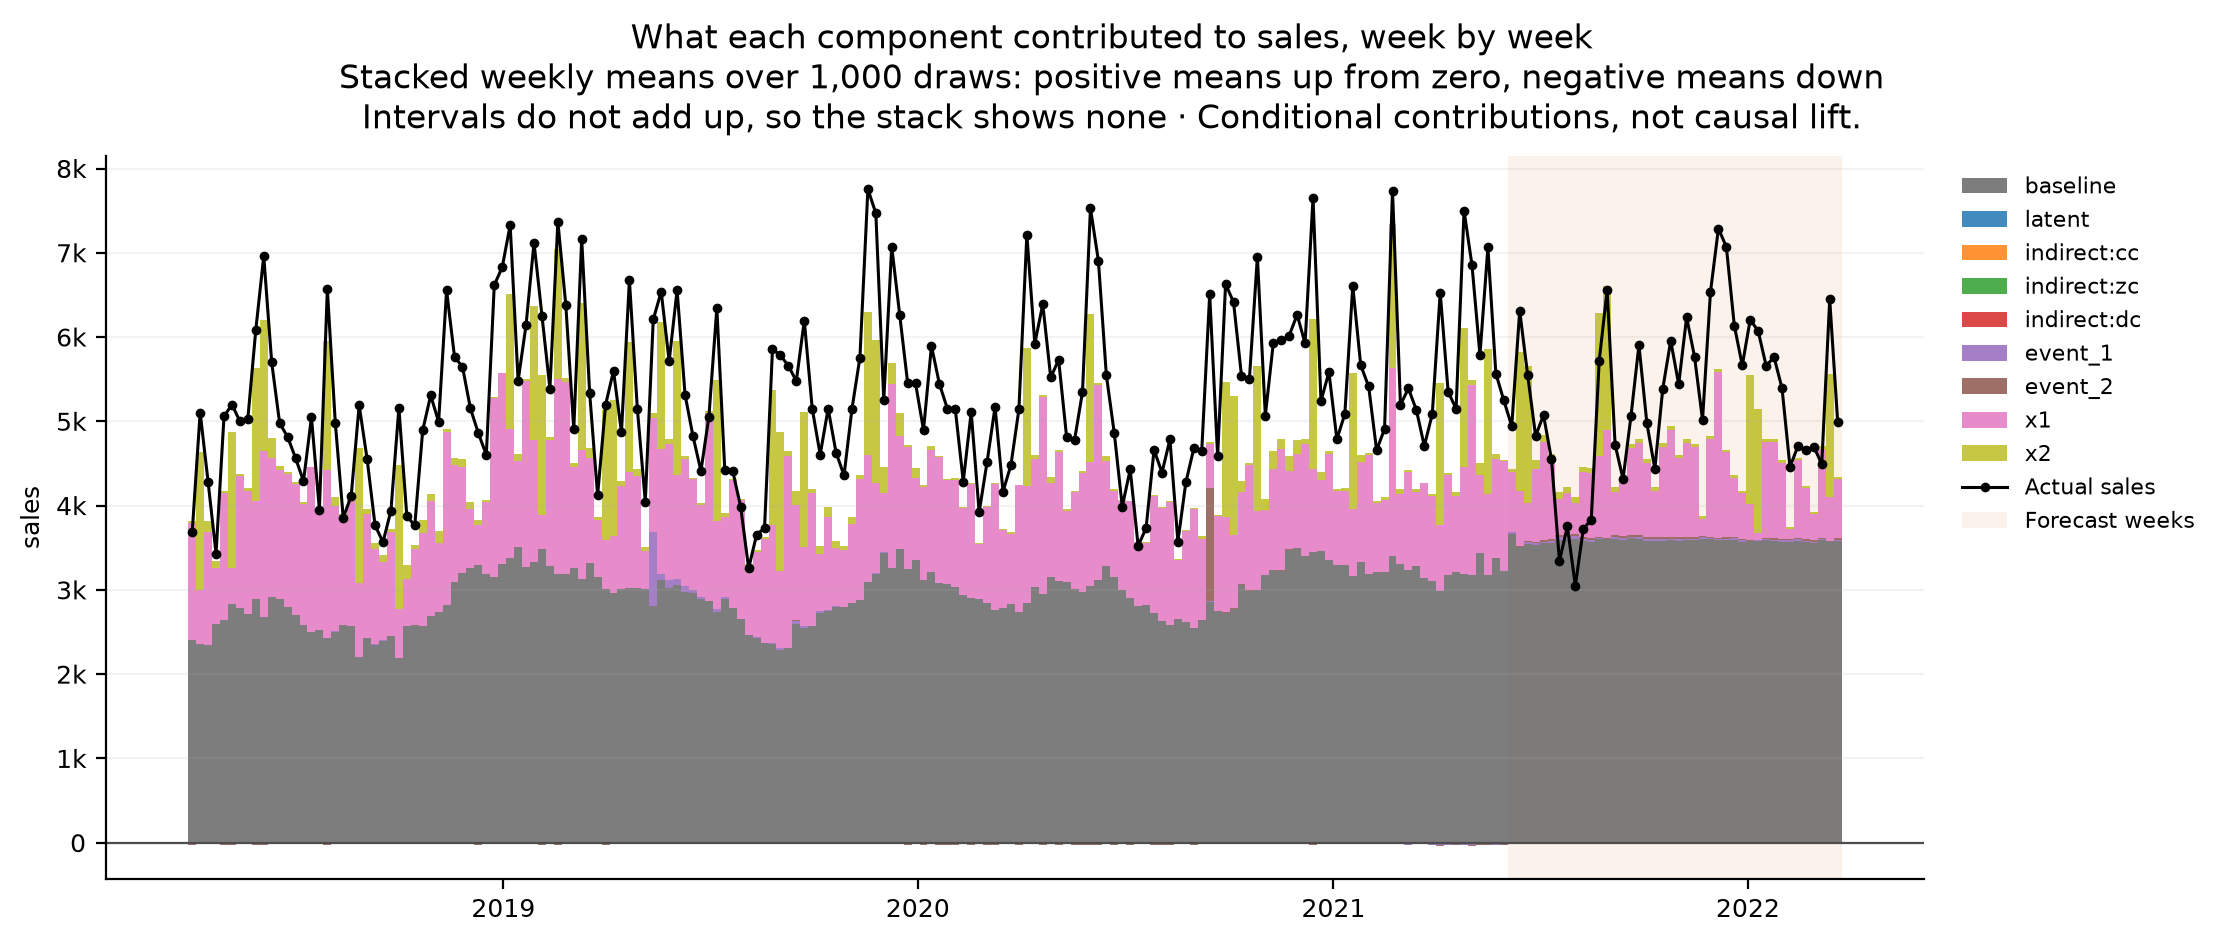

In [10]:
model.plot.contributions_over_time()

Each channel's and event's share of the expected sales in the context weeks, with its 90%
interval, and the posterior distribution of each share (`view="spread"`).

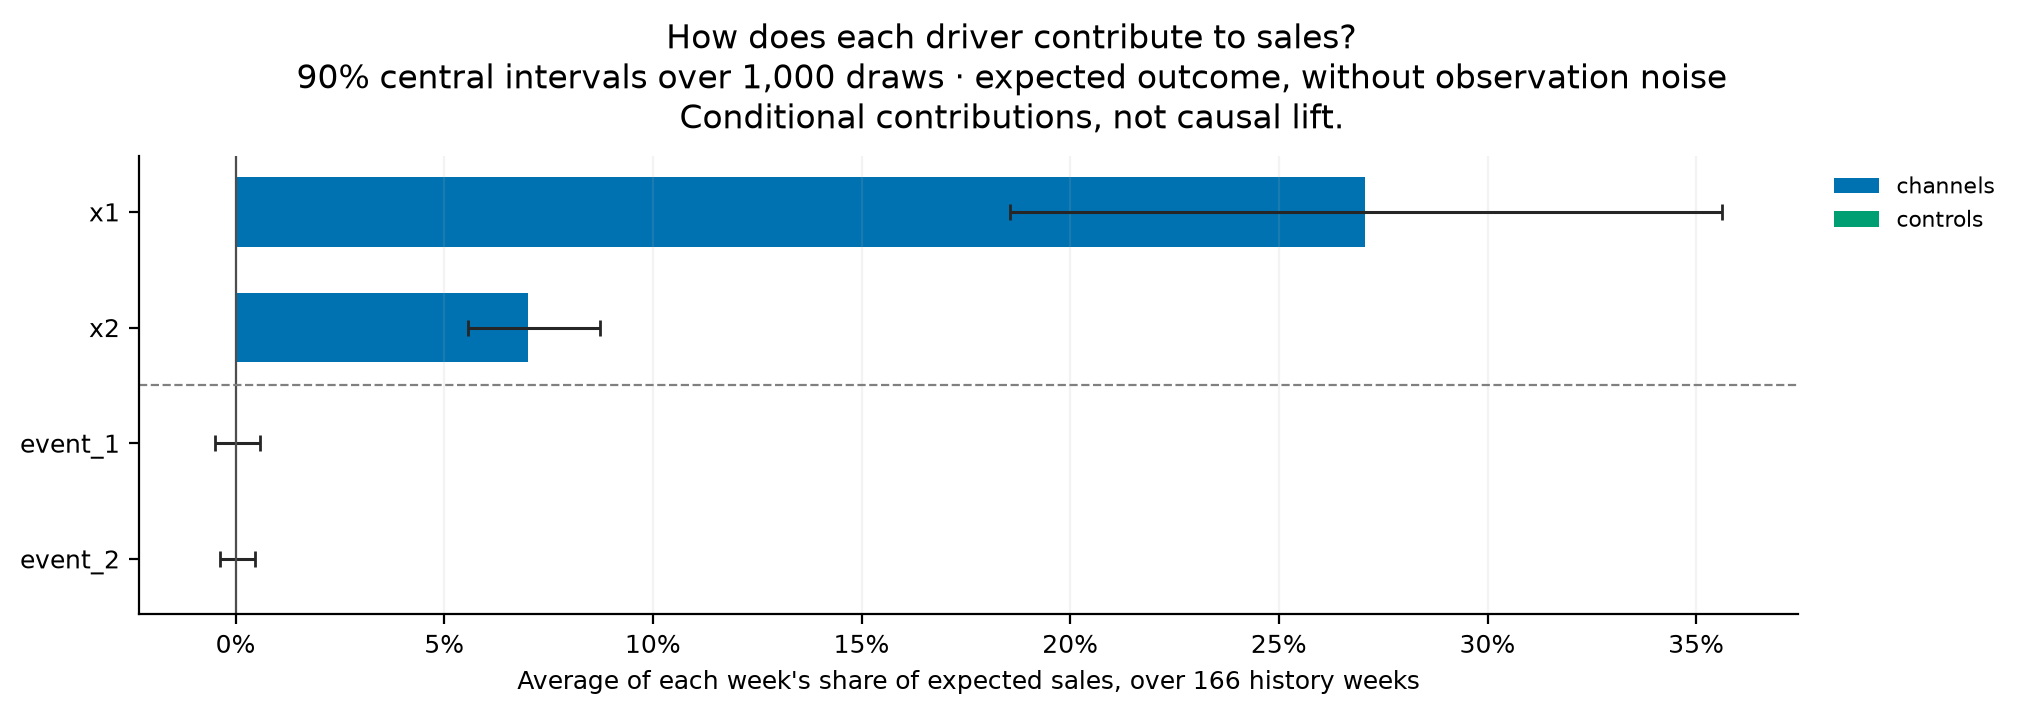

In [11]:
model.plot.shares()

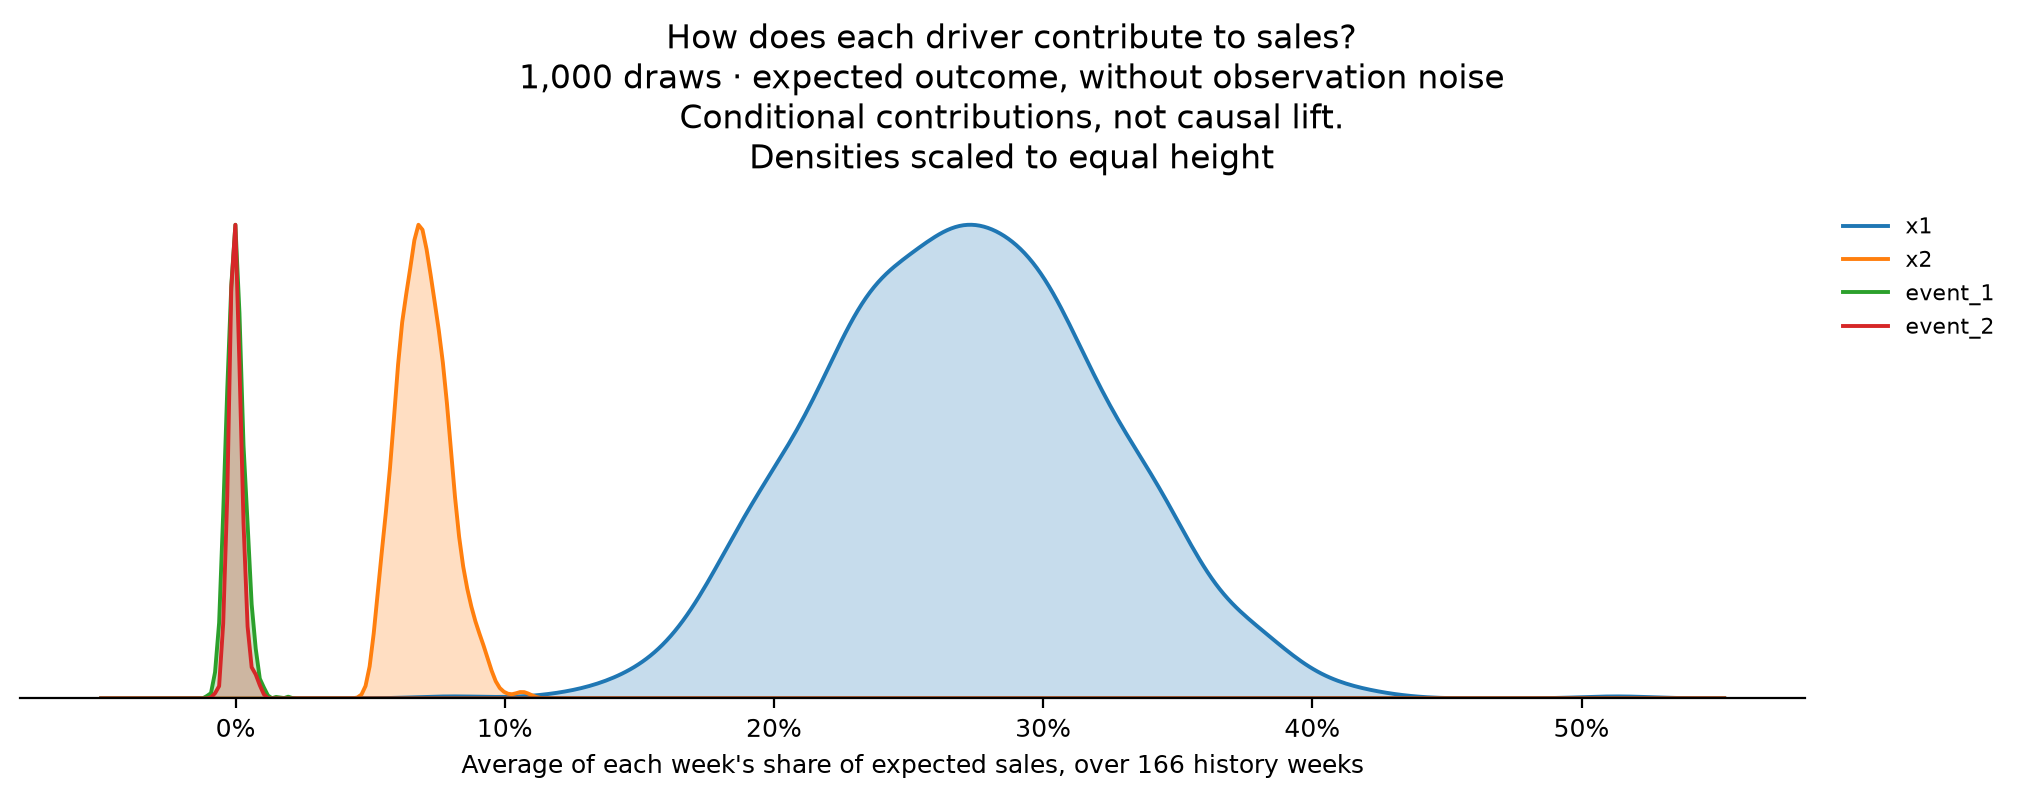

In [12]:
model.plot.shares(view="spread")

## 7. Recovery

Each channel's and event's weekly contribution, the posterior mean with its central 90% interval,
against the true contribution (dashed).

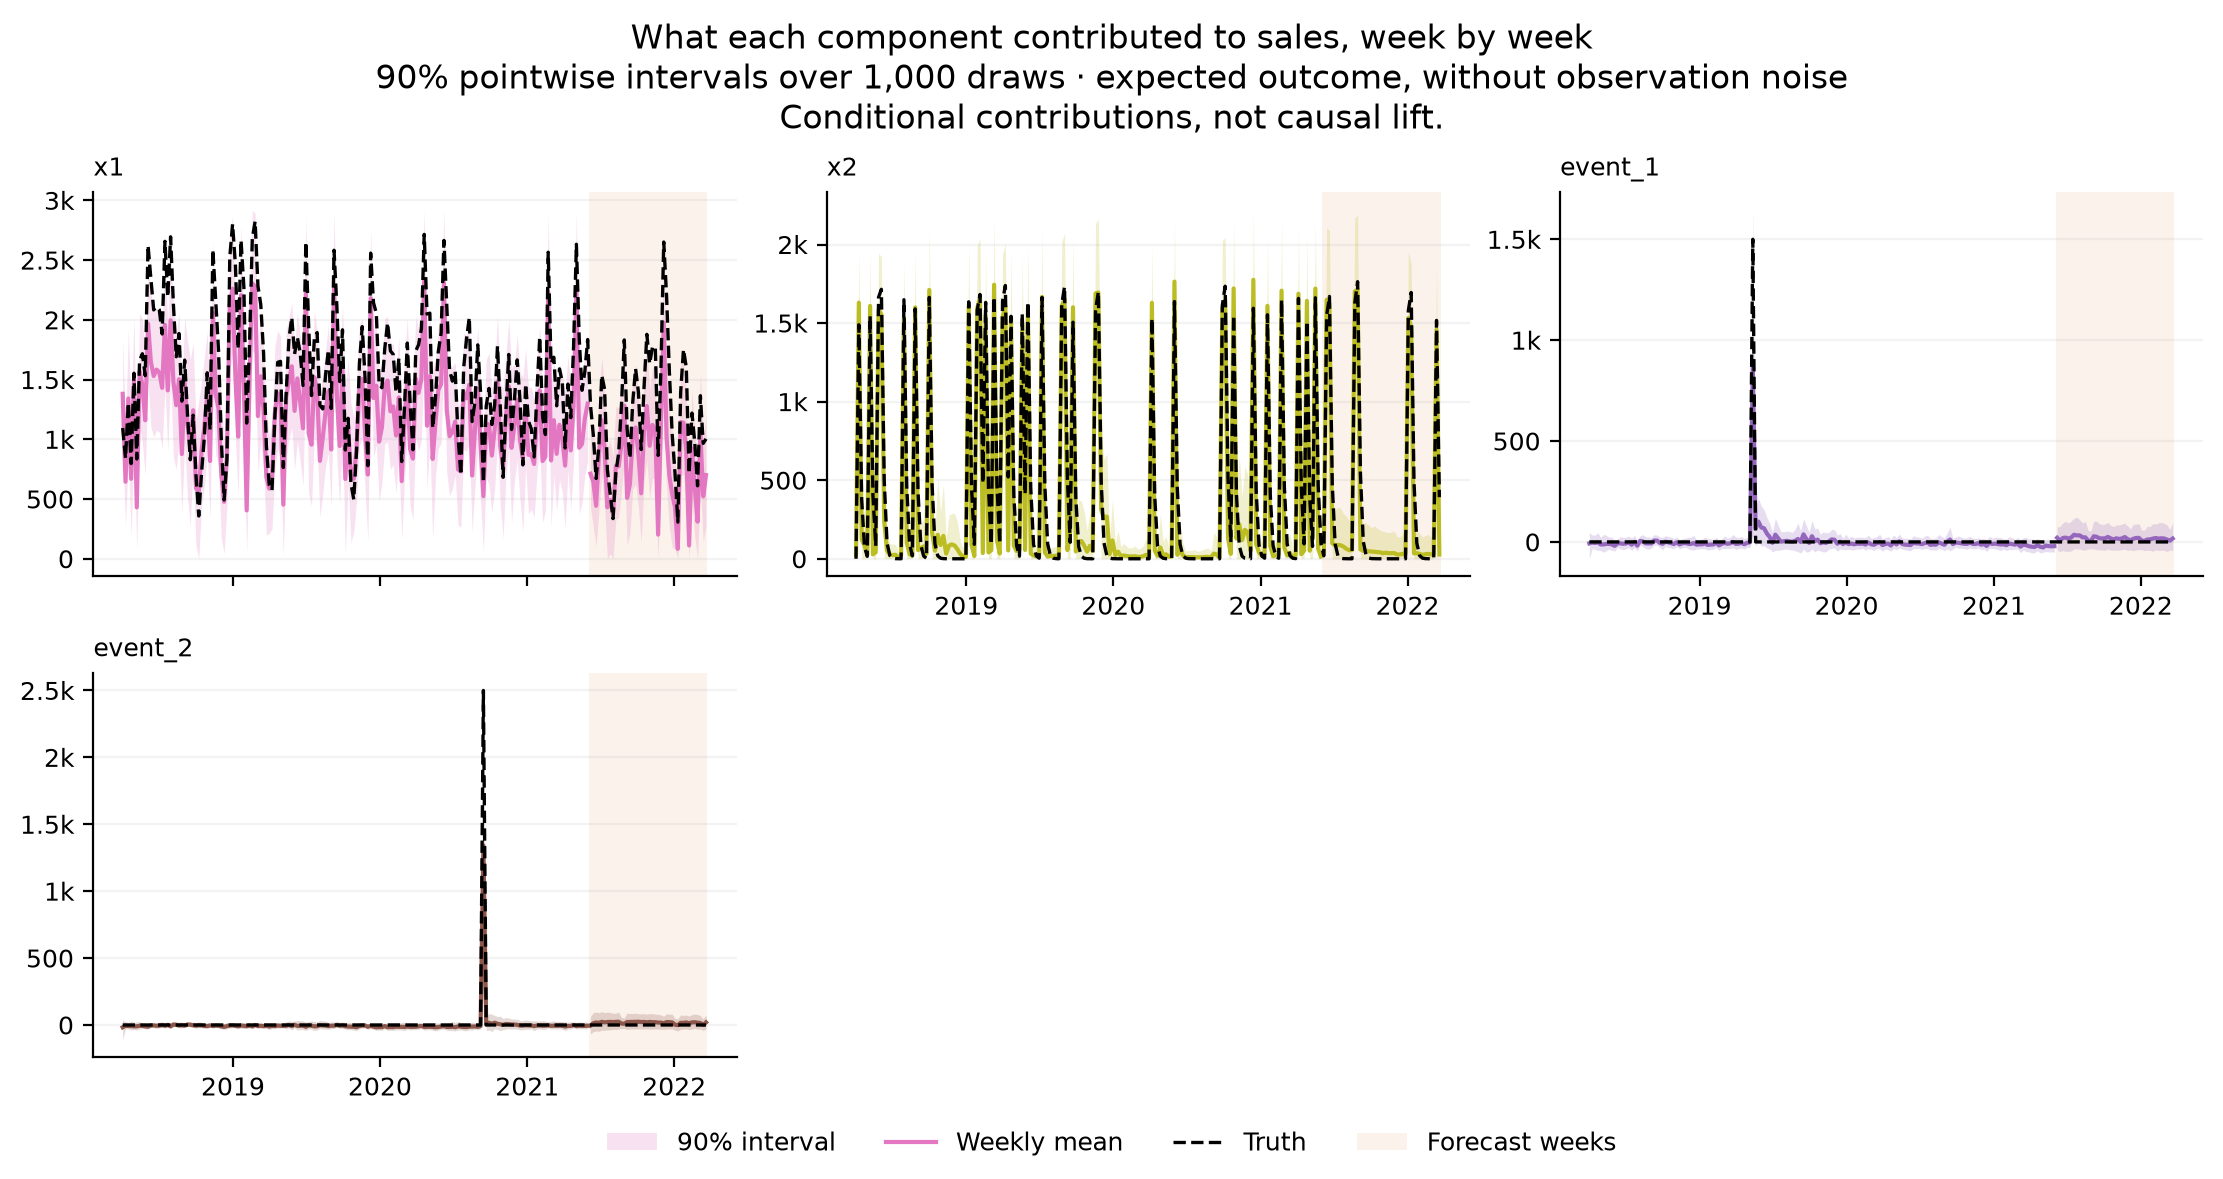

In [13]:
model.plot.contributions_over_time(
    stacked=False, components=["x1", "x2", "event_1", "event_2"], truth=truth
)

The posterior distribution of each effect's total over the window against its true value
(dashed). An event's total includes the part the model places in the weeks after the event.
Both events fall in the context weeks, so the query shows the channels only.

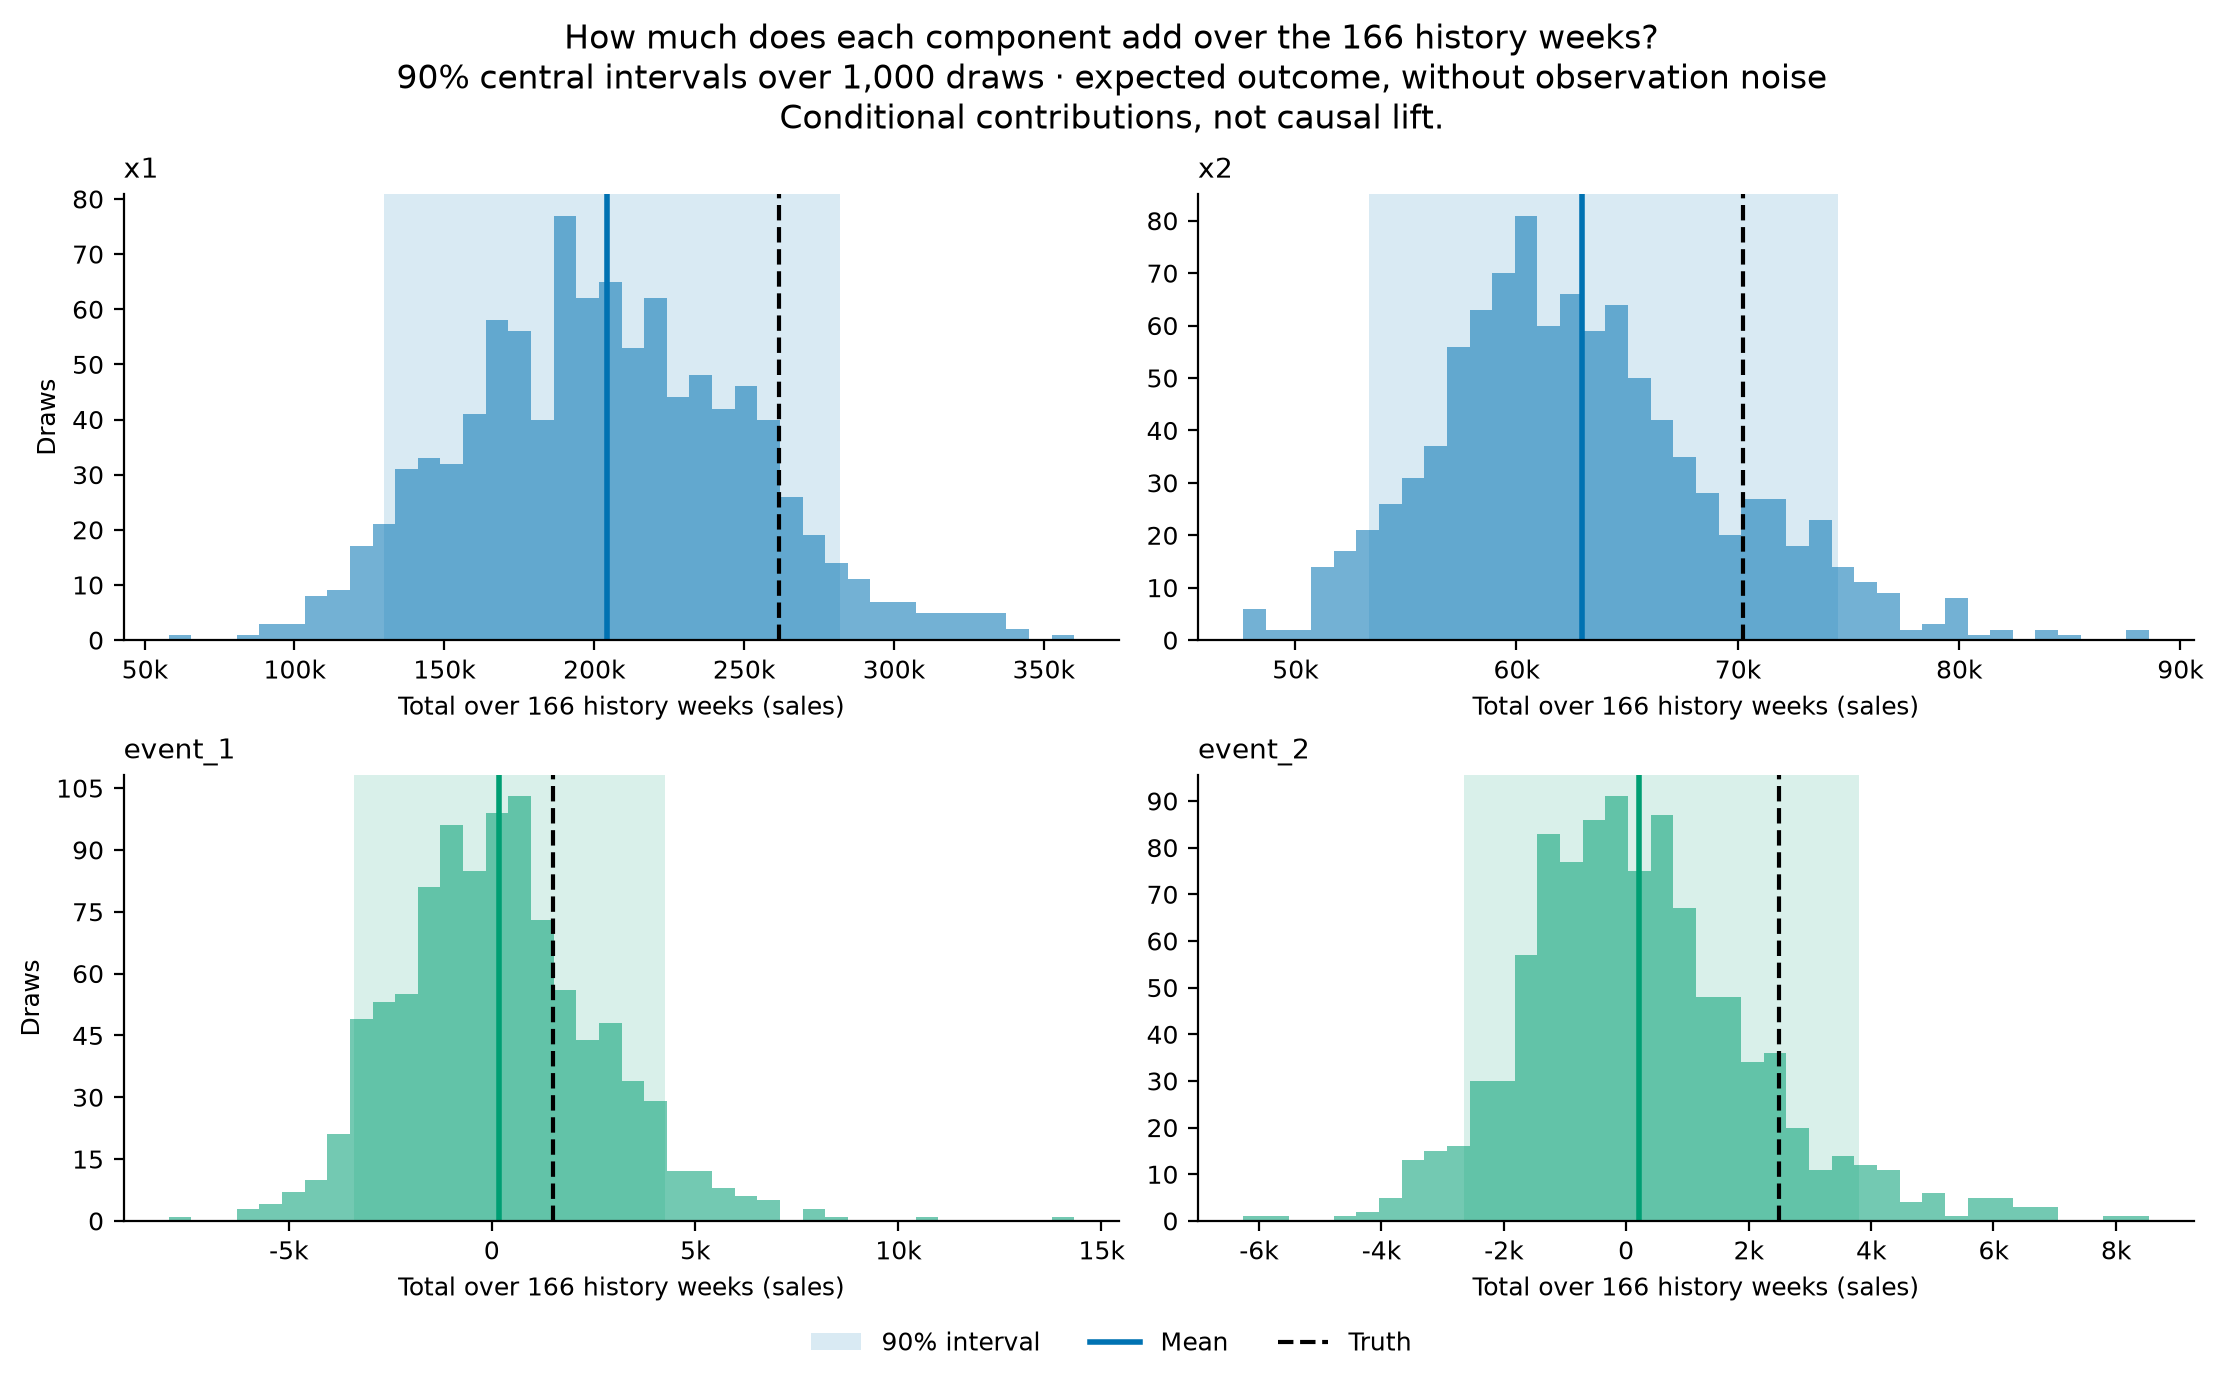

In [14]:
model.plot.contribution_totals(truth=truth)

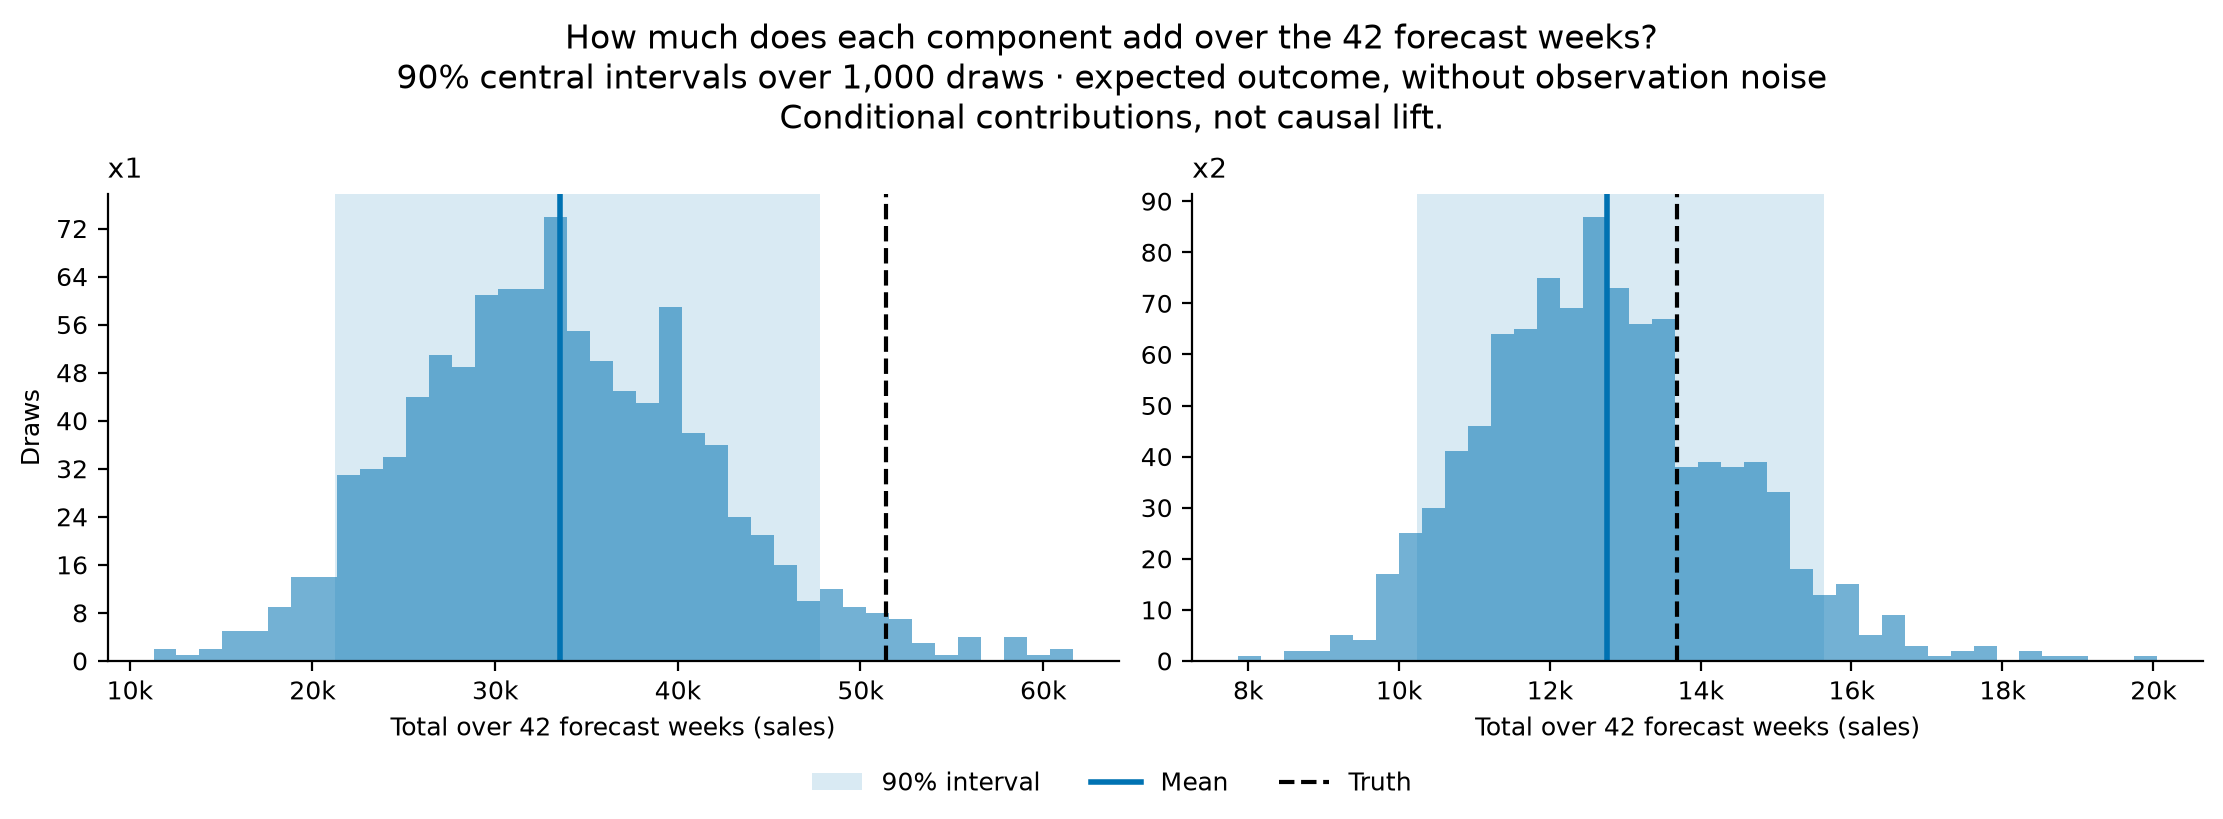

In [15]:
model.plot.contribution_totals(window="query", components=["x1", "x2"], truth=truth)

## 8. Context raw spend: River-1 versus simulated truth

One panel per channel, context weeks only: raw weekly spend against River-1's posterior mean
contribution (with its 90% interval) and the simulated true contribution (crosses). Contributions
depend on past spend as well as current spend, so points need not lie on a single curve.

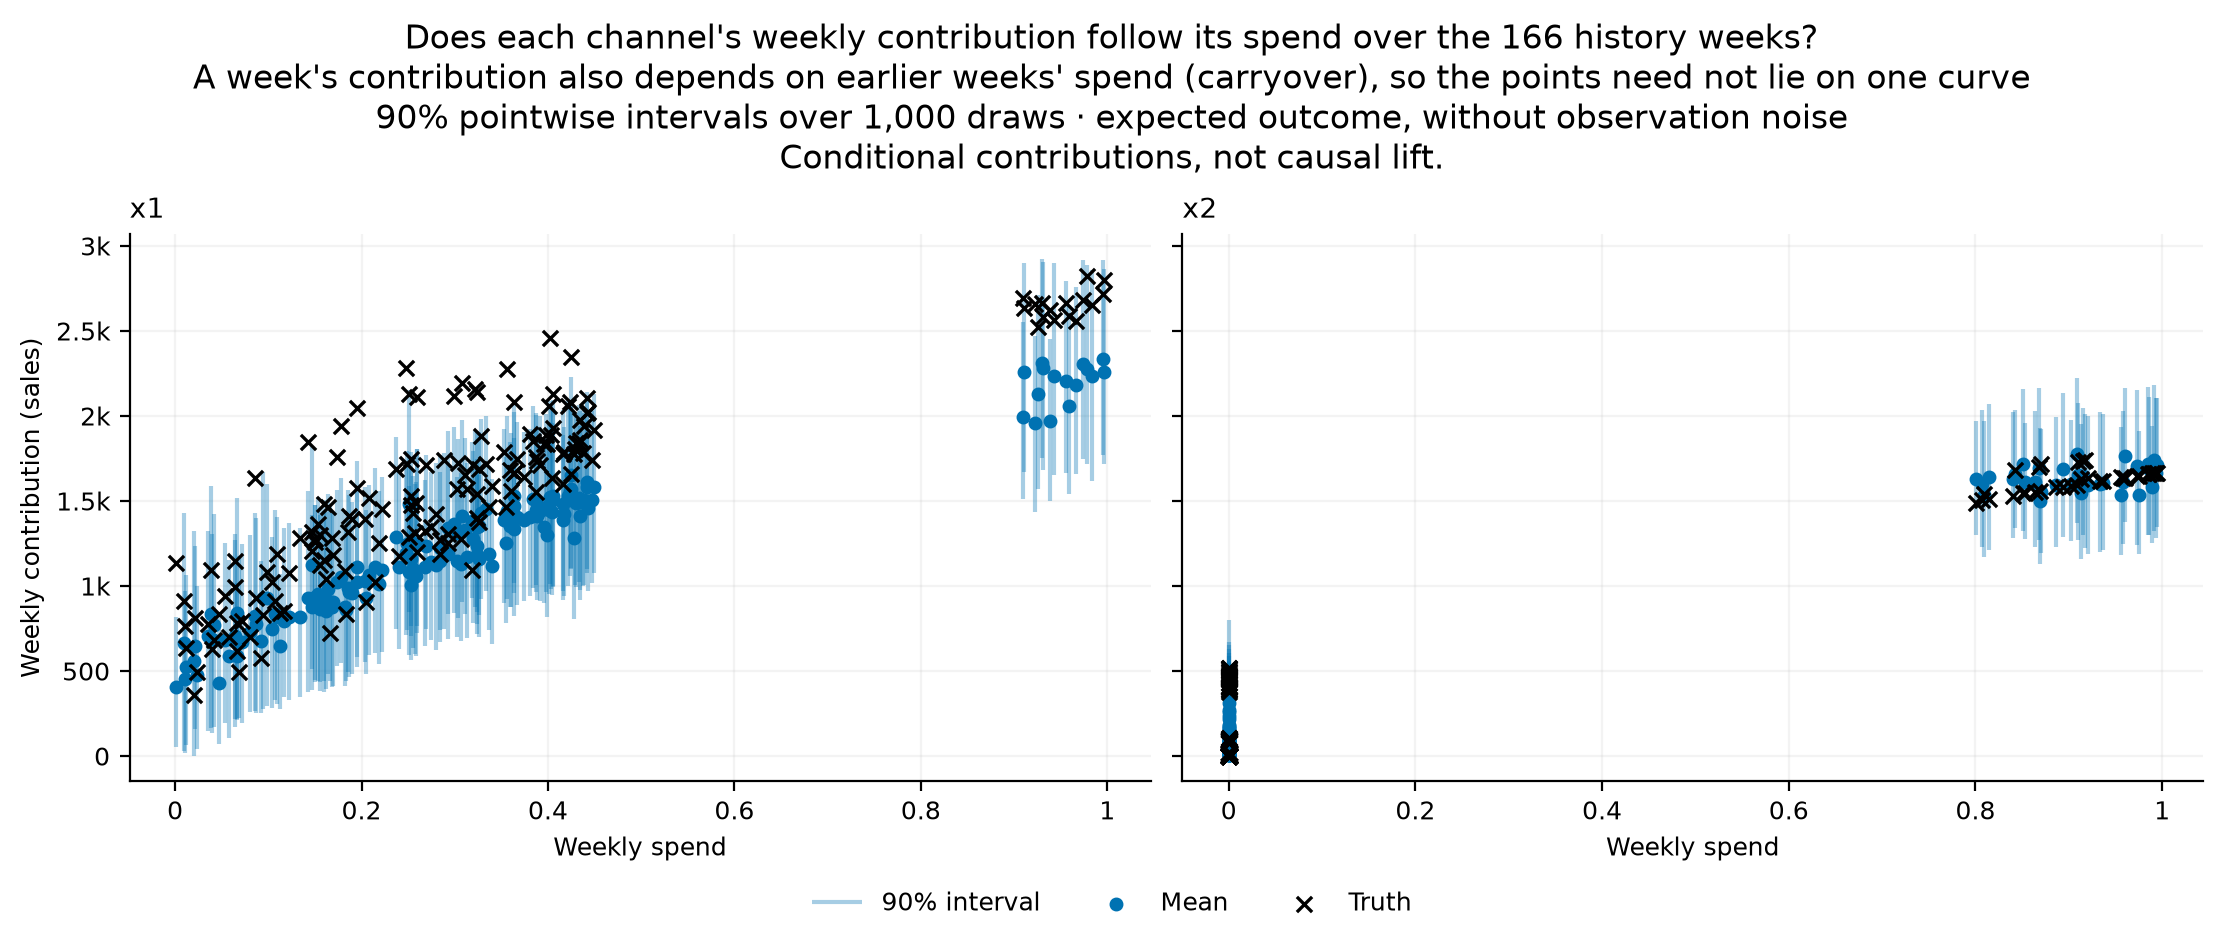

In [16]:
model.plot.contribution_vs_spend(truth=truth)

## 9. Sweep 0–200% of actual spend

`response_curves` multiplies one channel's actual spend path in the first eight query weeks by
each level, 0% to 200% in steps of 5%, and reruns inference over those eight weeks; the other
channel, the controls and the 166 context weeks stay unchanged. Each level is a separate
scenario with fresh draws, plus one unchanged reference at 100%. The curve sums the channel's
eight weekly contributions within each draw, then takes the posterior mean and central 90%
interval across draws. The calculation and the chart are separate calls, so the figure can be
restyled without resampling.

The black dots are the generator's true **adstock → logistic saturation → channel scaling** at
the same spend levels, in the same eight-week total-sales units, computed from the full spend
history. They exist because this example is simulated.

These are conditional channel-contribution curves, not identified causal lift, fitted saturation
functions or steady-state responses. Intervals are pointwise, not simultaneous curve bands, and
draws are not paired across levels. Zero new spend does not erase historical spend, so its
contribution need not be zero. Scenarios far from the observed spend, especially at 200%, can lie
outside the model's well-supported input patterns.

In [17]:
torch.manual_seed(0)
curves = model.response_curves(levels=np.linspace(0.0, 2.0, 41), weeks=8, n_samples=1_000)
curves.to_frame().query("level in (0.5, 1.0, 1.5)")

,channel,level,spend,mean,low,high
10,x1,0.5,0.635249,2583.822406,144.094213,6056.177809
20,x1,1.0,1.270498,4705.979541,1036.633059,8980.170705
30,x1,1.5,1.905747,7024.778200,2512.308099,12284.455913
51,x2,0.5,0.842430,2630.397649,1326.816479,4267.204191
61,x2,1.0,1.684860,4064.686629,2659.580804,5876.271518
71,x2,1.5,2.527290,4719.063217,2983.164504,7070.044780


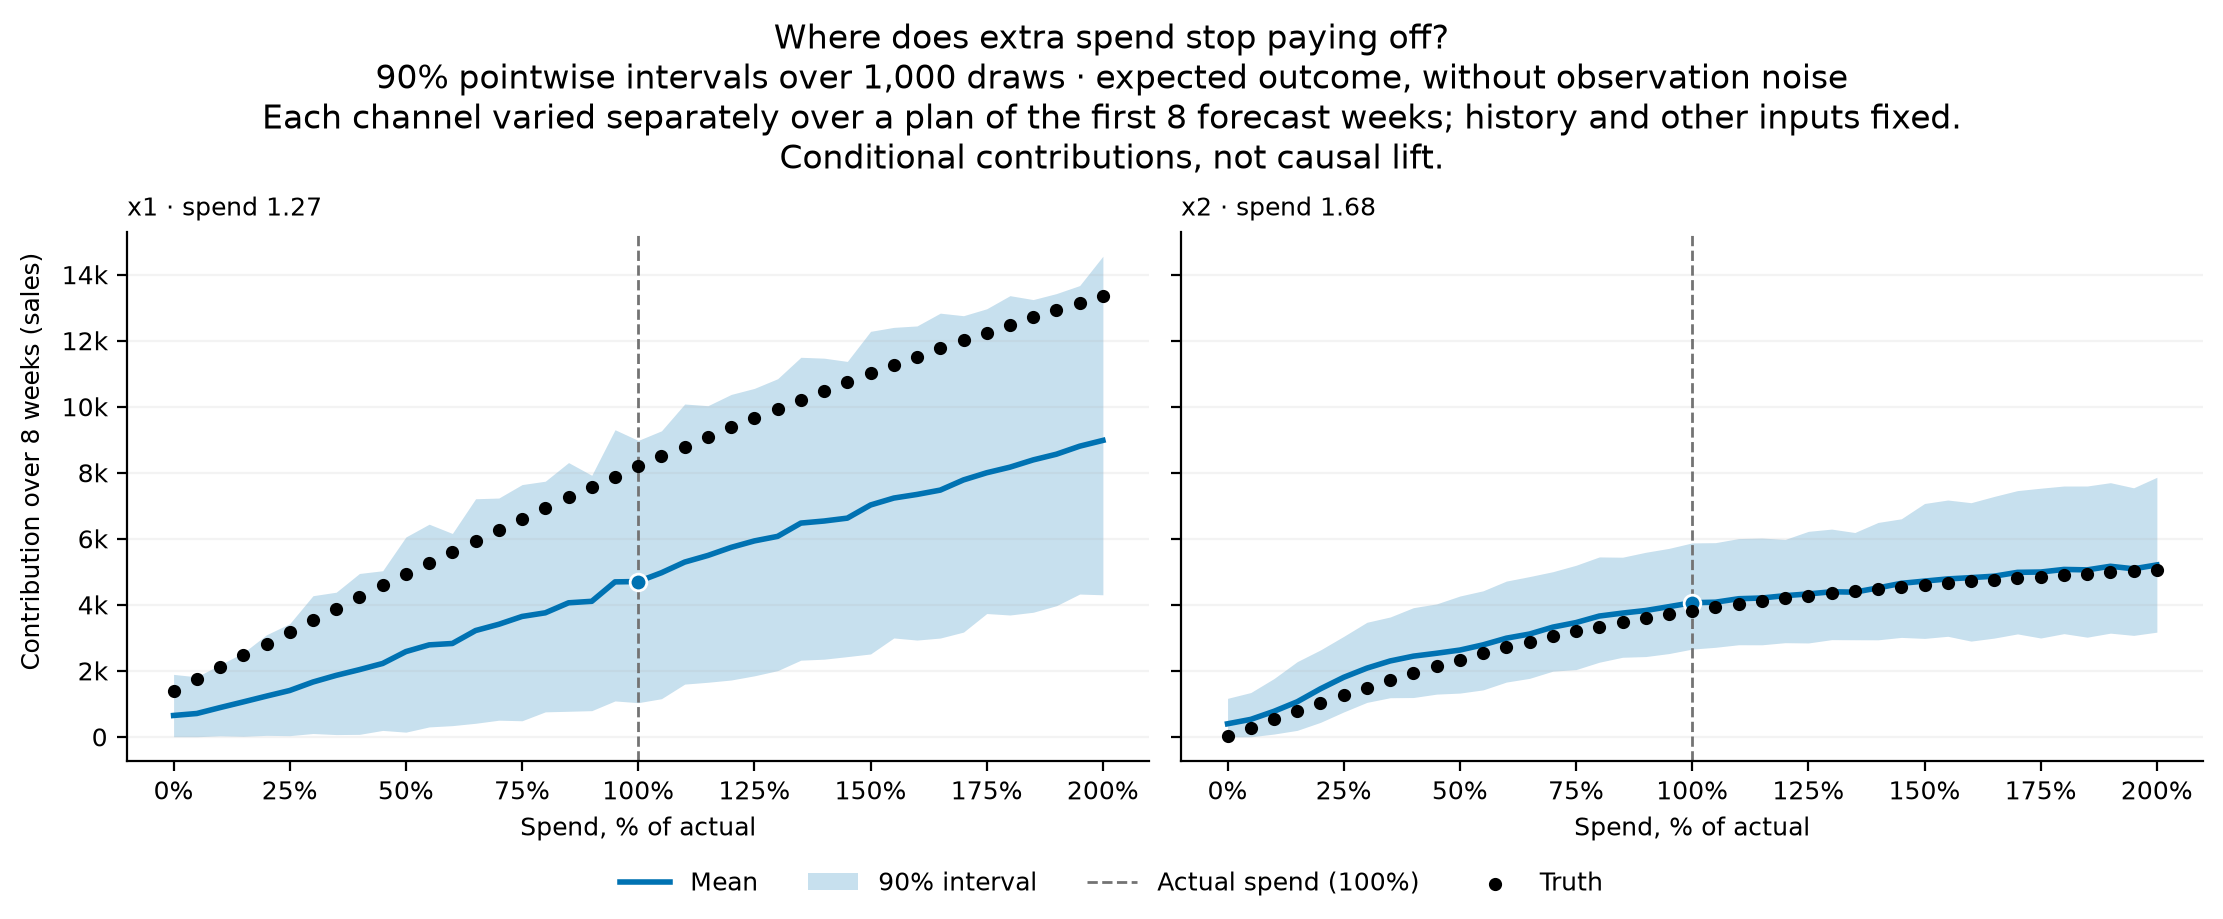

In [18]:
# The generator's true eight-week contribution at each level, from the full spend history.
sweep = slice(CONTEXT, CONTEXT + 8)
sweep_truth = {}
for name, parameters in media_parameters.items():
    paths = np.tile(data[name].to_numpy()[: sweep.stop], (len(curves.levels), 1))
    paths[:, sweep] *= curves.levels[:, None]
    adstocked = geometric_adstock(
        xr.DataArray(paths, dims=("level", "week")),
        alpha=parameters["alpha"],
        l_max=ADSTOCK_L_MAX,
        normalize=True,
        dim="week",
    )
    response = parameters["beta"] * logistic_saturation(adstocked, lam=parameters["lam"]).eval()
    sweep_truth[name] = SCALE * response[:, sweep].sum(axis=1)

model.plot.response_curves(truth=pd.DataFrame(sweep_truth, index=curves.levels))

## 10. Inspect the discovered graphs

Reuse the existing `query` draws: none of the plots below reruns inference. The graph nodes
use the configured names `channel:x1`, `channel:x2`, `control:event_1` and `control:event_2`,
plus the model's active latent nodes and the target node `outcome`. Padded controls are omitted.

The labels **Graph 0**, **Graph 1**, and so on are zero-based **ranks**, not permanent graph IDs:
rank 0 has the largest draw count; ties use the ascending binary edge vector. Ranks can change
after a new inference call. Frequencies are empirical draw frequencies, not goodness-of-fit
scores, effect strengths or evidence of causal identification.

### Average graph

The Average combines the marginal edge frequencies of all sampled graphs. Numeric arrow
labels show frequencies, not effect sizes. Diagrams use Graphviz's unmodified default
layout and rendering through its `dot` executable. Install Graphviz first, for example
with `brew install graphviz` on macOS or `sudo apt-get install graphviz` on Ubuntu.
Writing DOT source does not require Graphviz.

The Average may combine edges never sampled together and may contain cycles; it is not
necessarily one complete graph that the model sampled.

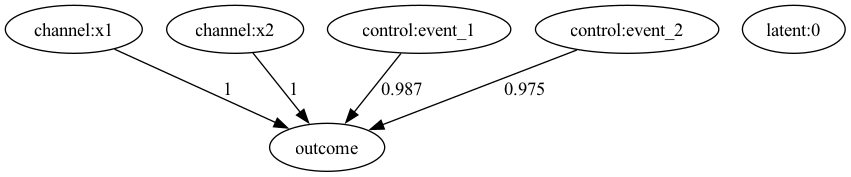

In [19]:
query.plot.dag()

### List graph ranks and inspect one topology

Build a table from the existing diagnostic evidence, using the same zero-based ordering
as the plots. `frequency` is a fraction from 0 to 1. `edge_count` counts the edges in that
complete graph, not the number of nonzero-frequency edges in the Average.

In [20]:
from IPython.display import display

graph_evidence = query.diagnostics().summary["arrays"]["graphs"]
graph_records = sorted(
    graph_evidence["complete_graphs"], key=lambda record: (-record["count"], record["graph"])
)
graph_catalog = pd.DataFrame(
    [
        {
            "graph_rank": rank,
            "draw_count": record["count"],
            "frequency": record["frequency"],
            "edge_count": sum(record["graph"]),
        }
        for rank, record in enumerate(graph_records)
    ]
).set_index("graph_rank")
graph_catalog

,draw_count,frequency,edge_count
graph_rank,,,
0,963,0.963,4
1,24,0.024,3
2,12,0.012,3
3,1,0.001,2


Change `selected_graph_rank` to any rank in the table. The connection table and diagram both
use that graph's exact binary edge vector; absent edges are not drawn. For an empty topology,
the connection table has no rows.

Graph 0: 963 draws; frequency 96.300%


,source,target
0,channel:x1,outcome
1,channel:x2,outcome
2,control:event_1,outcome
3,control:event_2,outcome


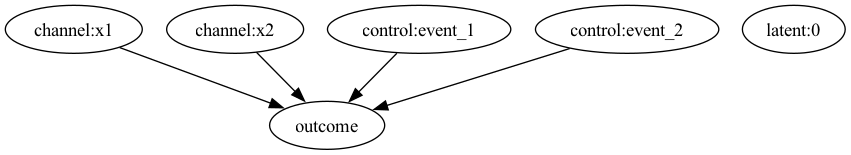

In [21]:
selected_graph_rank = 0
selected_graph = graph_records[selected_graph_rank]
selected_connections = [
    {"source": edge["endpoints"][0], "target": edge["endpoints"][1]}
    for edge, present in zip(graph_evidence["edges"], selected_graph["graph"], strict=True)
    if present
]
print(
    f"Graph {selected_graph_rank}: {selected_graph['count']} draws; "
    f"frequency {selected_graph['frequency']:.3%}"
)
display(pd.DataFrame(selected_connections, columns=["source", "target"]))
query.plot.dag(graph=selected_graph_rank)

### Plot several ranks, or all of them

Display the first three graphs to keep notebook output manageable. Set
`ranks_to_plot = list(graph_catalog.index)` to plot every discovered graph instead.
The printed captions identify each rank, draw count and frequency; the diagrams themselves
use Graphviz's defaults without custom styling.

Graph 0: 963 draws; frequency 96.300%


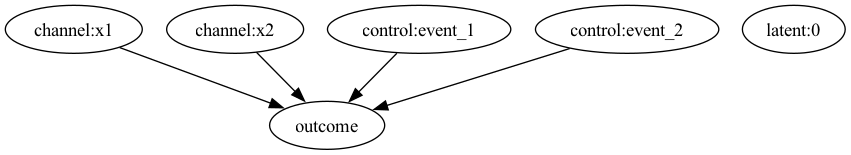

Graph 1: 24 draws; frequency 2.400%


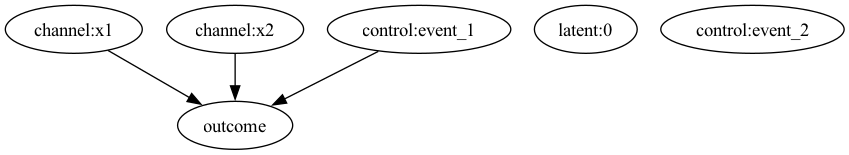

Graph 2: 12 draws; frequency 1.200%


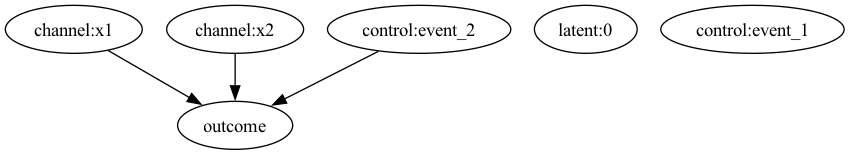

In [22]:
ranks_to_plot = list(graph_catalog.index[:3])
for graph_rank in ranks_to_plot:
    record = graph_records[int(graph_rank)]
    print(f"Graph {graph_rank}: {record['count']} draws; frequency {record['frequency']:.3%}")
    display(query.plot.dag(graph=int(graph_rank)))

### Export SVG and Graphviz DOT

Save the selected SVG and DOT source for both the Average and selected graph in the
temporary workspace. `query.plot.dot()` exports the Average; pass
`graph=selected_graph_rank` for an individual topology. No Graphviz installation is needed
to write DOT. Print the selected source below to inspect its named nodes and arrows.

Change `graph_export_dir` to a location you want to keep before running the final cleanup
cell. Exports contain graph topology, column labels and frequencies: review them before
sharing. They do not contain observation or contribution draws.

In [23]:
graph_export_dir = Path(workspace.name) / "graphs"
graph_export_dir.mkdir(exist_ok=True)
query.plot.dag(graph=selected_graph_rank).savefig(
    graph_export_dir / f"graph-{selected_graph_rank}.svg"
)
average_dot = query.plot.dot()
selected_dot = query.plot.dot(graph=selected_graph_rank)
(graph_export_dir / "graph-average.dot").write_text(average_dot, encoding="utf-8", newline="\n")
(graph_export_dir / f"graph-{selected_graph_rank}.dot").write_text(
    selected_dot, encoding="utf-8", newline="\n"
)
print("Saved the selected SVG and average/selected DOT in graph_export_dir.")
print(selected_dot)

Saved the selected SVG and average/selected DOT in graph_export_dir.
// Complete graph rank 0
// Prediction-only routing topology; supplied graph truth is not exported.
// Average shows marginal edge draw frequencies, not one complete sampled graph.
// Complete graph ranks show binary edges, ordered by count then binary vector.
// Frequencies are empirical router-draw frequencies, not fit or causal scores.
// MAP/fixed modes describe selected/supplied hypotheses, not posterior mass.
digraph {
  n0 [label="channel:x1"];
  n1 [label="outcome"];
  n2 [label="channel:x2"];
  n3 [label="latent:0"];
  n4 [label="control:event_1"];
  n5 [label="control:event_2"];
  n0 -> n1;
  n2 -> n1;
  n4 -> n1;
  n5 -> n1;
}



Optionally export **every** discovered graph:

```python
for graph_rank in graph_catalog.index:
    query.plot.dag(graph=int(graph_rank)).savefig(
        graph_export_dir / f"graph-{graph_rank}.svg"
    )
    (graph_export_dir / f"graph-{graph_rank}.dot").write_text(
        query.plot.dot(graph=int(graph_rank)), encoding="utf-8", newline="\n"
    )
```

The SVG export above is rendered by Graphviz's native engine, with its defaults unchanged.
To render a saved DOT file directly, run
`dot -Tsvg graph-0.dot -o graph-0-native.svg` in the export directory.

This can create many files; it is opt-in rather than part of Run All. All plots use the original
query draw bank, without resampling. MAP/fixed results contain only the selected/supplied
hypothesis, not the pre-selection graph distribution.

## Interactive charts

Every chart also draws with plotly (`pip install 'pymc-mfm[interactive]'`): pass
`backend="plotly"` to one chart, or set it for the whole session. Plotly figures zoom, show
values on hover and hide a series when you click its legend entry.

```python
model.plot.fit(backend="plotly")

from pymc_mfm.plotting import set_backend

set_backend("plotly")
model.plot.response_curves()
```

## 11. Recap

- **No fit.** River-1 decomposed the series with one `inference` call and 1,000 draws per
  window, and no model fitted to this dataset. It saw the sales of the 166 context weeks only.
- **Sales.** The expected sales follow the observed sales with a weekly MAPE of 14% in both
  windows. 75% of the context weeks and 38 of the 42 held-out query weeks (90%) fall inside the
  90% interval, which excludes observation noise.
- **Media split.** In the context, the x1 share of media contribution is 0.76 against a true 0.79.
  Both channel totals are inside their 90% intervals but below the truth (x1 204,329 against
  261,603; x2 62,940 against 70,252). x1 averages 27% of each week's expected sales, x2 7%.
- **Query channels.** The x2 total is recovered (12,756 against 13,690). x1 is underestimated:
  its truth (51,407) is above the 90% interval (21,219 to 47,795), and the x1 share drops to 0.72.
- **Events.** Both one-week events are placed in their week, but small contributions the model
  spreads over the other weeks bring their window totals near zero (168 and 202 against 1,500 and
  2,500), inside wide intervals.
- **Response curves.** Over the first eight query weeks, x2's curve follows the generator's
  saturating truth (4,065 against 3,825 at the actual spend). x1's curve rises with spend but
  stays below its truth (4,706 against 8,191 at the actual spend), inside a wide interval.
- **Posteriors.** Every effect is a distribution, not a point estimate: the panels, histograms
  and curves show its spread and where the truth falls in it. On this dataset River-1 leans
  towards under-attribution of x1, with wide intervals that usually, but not always, contain
  the truth.

In [24]:
workspace.cleanup()  # Delete the downloaded bundle.